# Laboratorio de Machine Learning — Unidad 2.1

Material de apoyo practico para la Unidad 2.1 (Inteligencia Artificial y Machine Learning)
del curso Estrategias de Transformacion Digital.

Este notebook asume que ya conocen los conceptos basicos de aprendizaje supervisado, no
supervisado y por refuerzo (vistos en el texto guia de la Unidad 2.1), y se enfoca en el
uso practico: como se implementan, que decisiones hay que tomar al construirlos, y como
se interpretan sus resultados. Cada celda de codigo incluye un comentario por linea
explicando que hace esa linea especificamente, no solo que hace el bloque en general.

Contenido:

1. Preprocesamiento de datos
2. Aprendizaje supervisado: clasificacion
3. Aprendizaje supervisado: regresion
4. Validacion cruzada y comparacion de modelos
5. Aprendizaje no supervisado: clustering
6. Reduccion de dimensionalidad (PCA)
7. Aprendizaje por refuerzo: Q-learning desde cero


## 0. Librerias

Todas las librerias usadas en este notebook son de codigo abierto y de uso estandar en la
industria: pandas y numpy para manejo de datos, scikit-learn para los modelos de machine
learning clasico, y matplotlib para las visualizaciones.

In [1]:
import numpy as np  # numpy: operaciones numericas vectorizadas y generacion de numeros aleatorios reproducibles
import pandas as pd  # pandas: estructuras tabulares (DataFrame) para manipular los datos
import matplotlib.pyplot as plt  # matplotlib: graficas para visualizar resultados

# Modulos de scikit-learn que se usaran mas adelante en el notebook
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV  # particion de datos y validacion cruzada
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # escalado numerico y codificacion categorica
from sklearn.compose import ColumnTransformer  # permite aplicar transformaciones distintas a columnas distintas
from sklearn.pipeline import Pipeline  # encadena preprocesamiento + modelo en un solo objeto reproducible
from sklearn.impute import SimpleImputer  # imputacion de valores faltantes

from sklearn.linear_model import LogisticRegression, LinearRegression  # modelos lineales (clasificacion y regresion)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor  # modelos de ensamble basados en arboles
from sklearn.cluster import KMeans  # algoritmo de clustering
from sklearn.decomposition import PCA  # reduccion de dimensionalidad

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,  # metricas de clasificacion
    confusion_matrix, classification_report,                   # reportes de clasificacion
    mean_absolute_error, mean_squared_error, r2_score,          # metricas de regresion
    silhouette_score,                                           # metrica de clustering
)

RANDOM_STATE = 42  # semilla fija: garantiza que los resultados sean reproducibles en cada ejecucion
np.random.seed(RANDOM_STATE)  # fija la semilla global de numpy para que los datos sinteticos sean siempre los mismos


## 1. Preprocesamiento de datos

En la practica, ningun dataset llega listo para entrenar un modelo. Antes de poder usar
cualquier algoritmo de machine learning hay que resolver, al menos, tres problemas: datos
faltantes, variables categoricas (texto) que el modelo no puede interpretar directamente, y
variables numericas en escalas muy distintas entre si. Esta seccion construye un dataset
sintetico que simula un caso de cancelacion de clientes (churn) con estos tres problemas a
proposito, para mostrar como se resuelven con herramientas estandar de scikit-learn.

In [2]:
n_clientes = 1000  # numero de clientes a simular en el dataset sintetico

# Se genera cada columna del dataset por separado, simulando atributos tipicos de un
# cliente de una empresa de telecomunicaciones
antiguedad_meses = np.random.randint(1, 72, size=n_clientes)  # meses que el cliente lleva activo, entre 1 y 72
consumo_mensual = np.random.gamma(shape=2.0, scale=30, size=n_clientes)  # consumo mensual en GB, distribucion asimetrica realista
numero_quejas = np.random.poisson(lam=0.5, size=n_clientes)  # numero de quejas registradas, la mayoria con 0 o 1
tipo_plan = np.random.choice(["basico", "intermedio", "premium"], size=n_clientes, p=[0.5, 0.35, 0.15])  # variable categorica: plan contratado
metodo_pago = np.random.choice(["tarjeta", "transferencia", "efectivo"], size=n_clientes)  # variable categorica: metodo de pago

# Se introducen valores faltantes a proposito en la columna de consumo mensual,
# para poder mostrar como se imputan mas adelante
indices_faltantes = np.random.choice(n_clientes, size=50, replace=False)  # se eligen 50 posiciones al azar, sin repetir
consumo_mensual[indices_faltantes] = np.nan  # esas posiciones se marcan como valor faltante (NaN)

# La variable objetivo (si el cliente cancela o no) se construye con una regla simple:
# a menor antiguedad, mayor consumo y mas quejas, mayor probabilidad de cancelar
probabilidad_cancela = (
    0.4 * (antiguedad_meses < 12).astype(float)  # clientes nuevos cancelan mas
    + 0.3 * (numero_quejas >= 1).astype(float)   # clientes con quejas cancelan mas
    + 0.1                                         # probabilidad base para todos los clientes
)
cancela = (np.random.rand(n_clientes) < probabilidad_cancela).astype(int)  # se sortea la cancelacion segun esa probabilidad

# Finalmente se ensamblan todas las columnas en un DataFrame de pandas
datos = pd.DataFrame({
    "antiguedad_meses": antiguedad_meses,
    "consumo_mensual_gb": consumo_mensual,
    "numero_quejas": numero_quejas,
    "tipo_plan": tipo_plan,
    "metodo_pago": metodo_pago,
    "cancela": cancela,
})

datos.head()  # muestra las primeras 5 filas para verificar que el dataset se construyo correctamente


,antiguedad_meses,consumo_mensual_gb,numero_quejas,tipo_plan,metodo_pago,cancela
0,52,59.649769,0,basico,transferencia,0
1,15,60.441930,0,intermedio,transferencia,0
2,61,28.620681,1,intermedio,efectivo,0
3,21,21.773890,0,basico,efectivo,0
4,24,9.204440,0,basico,efectivo,0


In [3]:
datos.isna().sum()  # cuenta cuantos valores faltantes (NaN) tiene cada columna, para confirmar donde estan los huecos


antiguedad_meses       0
consumo_mensual_gb    50
numero_quejas          0
tipo_plan              0
metodo_pago            0
cancela                0
dtype: int64

Para resolver los tres problemas al mismo tiempo (faltantes, categoricas, escalas distintas),
scikit-learn ofrece un patron llamado `ColumnTransformer`: permite aplicar una transformacion
distinta a cada grupo de columnas, y empaquetar todo en un solo objeto reutilizable.

In [4]:
columnas_numericas = ["antiguedad_meses", "consumo_mensual_gb", "numero_quejas"]  # columnas que son numeros
columnas_categoricas = ["tipo_plan", "metodo_pago"]  # columnas que son texto/categorias

# Pipeline para las columnas numericas: primero imputa los faltantes con la mediana,
# luego escala los valores para que todas las columnas queden en rangos comparables
transformador_numerico = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="median")),  # reemplaza cada NaN por la mediana de esa columna
    ("escalar", StandardScaler()),                   # resta la media y divide por la desviacion estandar
])

# Pipeline para las columnas categoricas: las convierte en columnas binarias (one-hot encoding)
transformador_categorico = Pipeline(steps=[
    ("codificar", OneHotEncoder(handle_unknown="ignore")),  # crea una columna binaria por cada categoria distinta
])

# El ColumnTransformer aplica cada pipeline a su grupo de columnas correspondiente
preprocesador = ColumnTransformer(transformers=[
    ("num", transformador_numerico, columnas_numericas),      # aplica el pipeline numerico a las columnas numericas
    ("cat", transformador_categorico, columnas_categoricas),  # aplica el pipeline categorico a las columnas categoricas
])


## 2. Aprendizaje supervisado: clasificacion

Con los datos preprocesados, se entrena un modelo de clasificacion para predecir si un
cliente va a cancelar su servicio. Se usa un `RandomForestClassifier`, un modelo de
ensamble que combina muchos arboles de decision, porque en la practica suele dar mejor
desempeno que un solo arbol o que una regresion logistica simple en datasets con variables
mixtas (numericas y categoricas) como este.

In [5]:
X = datos.drop(columns=["cancela"])  # variables predictoras: todo el dataset excepto la columna objetivo
y = datos["cancela"]  # variable objetivo: si el cliente cancelo (1) o no (0)

# Se divide el dataset en entrenamiento (70%) y prueba (30%)
# stratify=y asegura que la proporcion de clientes que cancelan sea similar en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print("Tamano de entrenamiento:", X_train.shape[0])  # numero de filas usadas para entrenar
print("Tamano de prueba:", X_test.shape[0])  # numero de filas reservadas para evaluar
print("Proporcion de cancelacion en entrenamiento:", round(y_train.mean(), 3))  # fraccion de clientes que cancelan en train
print("Proporcion de cancelacion en prueba:", round(y_test.mean(), 3))  # fraccion de clientes que cancelan en test


Tamano de entrenamiento: 700
Tamano de prueba: 300
Proporcion de cancelacion en entrenamiento: 0.299
Proporcion de cancelacion en prueba: 0.297


In [6]:
# El Pipeline encadena el preprocesador (definido en la seccion 1) con el modelo de clasificacion
# Esto garantiza que la MISMA transformacion aprendida en entrenamiento se aplique en prueba,
# evitando fugas de informacion (data leakage) entre los dos conjuntos
modelo_clasificacion = Pipeline(steps=[
    ("preprocesamiento", preprocesador),  # aplica imputacion, escalado y codificacion
    ("modelo", RandomForestClassifier(
        n_estimators=200,       # numero de arboles en el bosque
        max_depth=6,            # profundidad maxima de cada arbol, limita el sobreajuste
        random_state=RANDOM_STATE,  # semilla para que el entrenamiento sea reproducible
    )),
])

modelo_clasificacion.fit(X_train, y_train)  # entrena el pipeline completo usando solo los datos de entrenamiento
y_pred = modelo_clasificacion.predict(X_test)  # genera las predicciones sobre el conjunto de prueba, nunca visto en entrenamiento


In [7]:
# Calculo de las metricas principales de clasificacion, explicadas en el texto guia de la Unidad 2.1
exactitud = accuracy_score(y_test, y_pred)  # proporcion de predicciones correctas sobre el total
precision = precision_score(y_test, y_pred)  # de los predichos como "cancela", cuantos realmente cancelaron
exhaustividad = recall_score(y_test, y_pred)  # de los que realmente cancelaron, cuantos detecto el modelo
f1 = f1_score(y_test, y_pred)  # media armonica entre precision y exhaustividad

print("Exactitud (accuracy):", round(exactitud, 3))
print("Precision:", round(precision, 3))
print("Exhaustividad (recall):", round(exhaustividad, 3))
print("F1-score:", round(f1, 3))

print("\nMatriz de confusion:")
print(confusion_matrix(y_test, y_pred))  # filas = real, columnas = predicho; diagonal = aciertos

print("\nReporte de clasificacion completo:")
print(classification_report(y_test, y_pred))  # resume precision, recall y f1 por cada clase


Exactitud (accuracy): 0.717
Precision: 0.537
Exhaustividad (recall): 0.326
F1-score: 0.406

Matriz de confusion:
[[186  25]
 [ 60  29]]

Reporte de clasificacion completo:
              precision    recall  f1-score   support

           0       0.76      0.88      0.81       211
           1       0.54      0.33      0.41        89

    accuracy                           0.72       300
   macro avg       0.65      0.60      0.61       300
weighted avg       0.69      0.72      0.69       300



Un detalle importante para interpretar un modelo de negocio, mas alla de las metricas
agregadas, es entender que variables esta usando el modelo para decidir. En un
`RandomForestClassifier` esto se puede inspeccionar con `feature_importances_`.

In [8]:
# Se recuperan los nombres finales de las columnas despues del preprocesamiento
# (el OneHotEncoder genera nuevas columnas, una por cada categoria)
nombres_numericos = columnas_numericas  # las columnas numericas no cambian de nombre
nombres_categoricos = list(
    modelo_clasificacion.named_steps["preprocesamiento"]  # accede al ColumnTransformer dentro del pipeline
    .named_transformers_["cat"]                            # accede al pipeline categorico
    .named_steps["codificar"]                               # accede al OneHotEncoder ya entrenado
    .get_feature_names_out(columnas_categoricas)             # obtiene los nombres de las columnas generadas
)
nombres_finales = nombres_numericos + nombres_categoricos  # lista completa de nombres de columnas tras el preprocesamiento

importancias = modelo_clasificacion.named_steps["modelo"].feature_importances_  # importancia de cada columna segun el bosque

# Se construye una tabla ordenada de mayor a menor importancia, para facilitar la lectura
tabla_importancias = pd.DataFrame({
    "variable": nombres_finales,
    "importancia": importancias,
}).sort_values("importancia", ascending=False)

tabla_importancias  # muestra la tabla completa ordenada


,variable,importancia
0,antiguedad_meses,0.475581
1,consumo_mensual_gb,0.232263
2,numero_quejas,0.170603
5,tipo_plan_premium,0.025076
6,metodo_pago_efectivo,0.022992
3,tipo_plan_basico,0.019944
4,tipo_plan_intermedio,0.019160
7,metodo_pago_tarjeta,0.017562
8,metodo_pago_transferencia,0.016819


## 3. Aprendizaje supervisado: regresion

El mismo flujo de trabajo (preprocesar, entrenar, predecir, evaluar) aplica a un problema
de regresion, donde la variable objetivo es un numero en lugar de una categoria. Aqui se
simula un caso de prediccion de precio de arriendo de una propiedad a partir de sus
caracteristicas.

In [9]:
n_propiedades = 800  # numero de propiedades a simular

area_m2 = np.random.uniform(30, 200, size=n_propiedades)  # area en metros cuadrados, entre 30 y 200
habitaciones = np.random.randint(1, 5, size=n_propiedades)  # numero de habitaciones, entre 1 y 4
antiguedad_anios = np.random.randint(0, 40, size=n_propiedades)  # antiguedad de la propiedad en anios
barrio = np.random.choice(["centro", "norte", "sur"], size=n_propiedades)  # variable categorica: ubicacion

# El precio se construye como una combinacion lineal de las variables, mas ruido aleatorio,
# para simular un patron realista pero no perfectamente determinista
ruido = np.random.normal(0, 150000, size=n_propiedades)  # ruido aleatorio que ningun modelo podra explicar
precio = (
    3_000_000                      # precio base
    + area_m2 * 35_000             # cada metro cuadrado adicional suma a el precio
    + habitaciones * 200_000       # cada habitacion adicional suma al precio
    - antiguedad_anios * 15_000    # cada anio de antiguedad resta al precio
    + ruido
)

propiedades = pd.DataFrame({
    "area_m2": area_m2,
    "habitaciones": habitaciones,
    "antiguedad_anios": antiguedad_anios,
    "barrio": barrio,
    "precio": precio,
})

propiedades.head()  # verifica que el dataset se construyo correctamente


,area_m2,habitaciones,antiguedad_anios,barrio,precio
0,69.862281,3,18,centro,5.815458e+06
1,111.710165,3,26,norte,7.075446e+06
2,123.810885,4,24,norte,7.800642e+06
3,137.401723,2,39,sur,7.719260e+06
4,73.710146,1,37,norte,5.081415e+06


In [10]:
X_reg = propiedades.drop(columns=["precio"])  # variables predictoras
y_reg = propiedades["precio"]  # variable objetivo numerica (precio)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=RANDOM_STATE  # misma logica de particion que en clasificacion
)

# Preprocesador especifico para este dataset: una columna categorica (barrio), dos numericas
preprocesador_reg = ColumnTransformer(transformers=[
    ("num", StandardScaler(), ["area_m2", "habitaciones", "antiguedad_anios"]),  # escala las columnas numericas
    ("cat", OneHotEncoder(), ["barrio"]),  # codifica la columna categorica
])

modelo_regresion = Pipeline(steps=[
    ("preprocesamiento", preprocesador_reg),  # aplica el preprocesamiento definido arriba
    ("modelo", RandomForestRegressor(
        n_estimators=200,  # numero de arboles en el bosque
        max_depth=8,        # profundidad maxima de cada arbol
        random_state=RANDOM_STATE,  # semilla para reproducibilidad
    )),
])

modelo_regresion.fit(X_train_r, y_train_r)  # entrena el pipeline completo con los datos de entrenamiento
y_pred_r = modelo_regresion.predict(X_test_r)  # genera predicciones sobre el conjunto de prueba


In [11]:
mae = mean_absolute_error(y_test_r, y_pred_r)  # error absoluto promedio, en las mismas unidades que el precio
rmse = mean_squared_error(y_test_r, y_pred_r) ** 0.5  # raiz del error cuadratico medio, penaliza mas los errores grandes
r2 = r2_score(y_test_r, y_pred_r)  # proporcion de la variabilidad del precio que el modelo logra explicar

print("Error absoluto promedio (MAE):", round(mae, 0))
print("Raiz del error cuadratico medio (RMSE):", round(rmse, 0))
print("R2 (proporcion de varianza explicada):", round(r2, 3))


Error absoluto promedio (MAE): 153728.0
Raiz del error cuadratico medio (RMSE): 191206.0
R2 (proporcion de varianza explicada): 0.987


## 4. Validacion cruzada y comparacion de modelos

Evaluar un modelo con una sola particion de entrenamiento/prueba puede dar una estimacion
poco estable del desempeno real, porque depende de que filas quedaron en cada conjunto. La
validacion cruzada (cross-validation) resuelve esto repitiendo el proceso de entrenar y
evaluar varias veces, con particiones distintas cada vez, y promediando el resultado.

In [12]:
# Se comparan dos modelos de clasificacion distintos sobre el mismo dataset de churn,
# usando validacion cruzada de 5 particiones (5-fold cross-validation)
modelos_a_comparar = {
    "Regresion logistica": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),  # modelo lineal simple
    "Bosque aleatorio": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE),  # modelo de ensamble
}

for nombre_modelo, modelo in modelos_a_comparar.items():  # itera sobre cada modelo a comparar
    pipeline_comparacion = Pipeline(steps=[
        ("preprocesamiento", preprocesador),  # mismo preprocesamiento para ambos modelos, para que la comparacion sea justa
        ("modelo", modelo),                    # el modelo actual del bucle
    ])
    puntajes = cross_val_score(
        pipeline_comparacion, X, y,  # pipeline y datos completos (la funcion hace la particion internamente)
        cv=5,                         # numero de particiones (folds)
        scoring="f1",                 # metrica a promediar en cada particion
    )
    print(f"{nombre_modelo}: F1 promedio = {puntajes.mean():.3f} (desviacion = {puntajes.std():.3f})")  # imprime el resultado promedio y su variabilidad


Regresion logistica: F1 promedio = 0.270 (desviacion = 0.045)


Bosque aleatorio: F1 promedio = 0.391 (desviacion = 0.057)


## 5. Aprendizaje no supervisado: clustering

Se simula un dataset de clientes descritos por dos variables de comportamiento
(frecuencia de compra y gasto promedio), sin ninguna etiqueta, y se usa K-Means para
encontrar grupos naturales. Antes de fijar el numero de grupos, se usa el metodo del codo
para decidir cuantos clusters tiene sentido buscar.

In [13]:
n_clientes_cluster = 400  # numero de clientes a simular para el ejercicio de clustering

# Se generan 4 grupos de clientes con comportamientos distintos, para que el clustering
# tenga una estructura real que descubrir
centros_reales = [(5, 50_000), (20, 40_000), (5, 150_000), (25, 180_000)]  # (frecuencia de compra, gasto promedio) de cada grupo
datos_cluster = []  # lista donde se acumularan los puntos generados

for centro_frecuencia, centro_gasto in centros_reales:  # itera sobre cada centro real
    frecuencia = np.random.normal(centro_frecuencia, 2, size=100)  # frecuencia de compra alrededor del centro, con ruido
    gasto = np.random.normal(centro_gasto, 15_000, size=100)  # gasto promedio alrededor del centro, con ruido
    datos_cluster.append(np.column_stack([frecuencia, gasto]))  # combina ambas columnas y las agrega a la lista

X_cluster = np.vstack(datos_cluster)  # apila los 4 grupos en una sola matriz de datos
np.random.shuffle(X_cluster)  # mezcla las filas para que no queden ordenadas por grupo

# Las dos variables tienen escalas muy distintas (frecuencia: decenas, gasto: cientos de miles),
# por lo que es indispensable escalarlas antes de aplicar K-Means, que se basa en distancias
escalador_cluster = StandardScaler()  # crea el escalador
X_cluster_escalado = escalador_cluster.fit_transform(X_cluster)  # ajusta y aplica el escalado en un solo paso


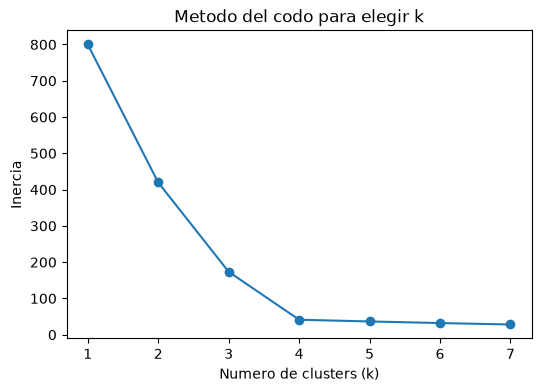

In [14]:
inercias = []  # lista donde se guardara la inercia (suma de distancias al centro) para cada numero de clusters probado
rango_k = range(1, 8)  # se probaran entre 1 y 7 clusters

for k in rango_k:  # itera sobre cada valor posible de k
    kmeans_prueba = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)  # crea el modelo con k clusters
    kmeans_prueba.fit(X_cluster_escalado)  # entrena el modelo con los datos escalados
    inercias.append(kmeans_prueba.inertia_)  # guarda la inercia resultante (que tan compactos quedaron los grupos)

plt.figure(figsize=(6, 4))  # crea una figura de tamano moderado
plt.plot(list(rango_k), inercias, marker="o")  # grafica la inercia contra el numero de clusters, con marcadores circulares
plt.xlabel("Numero de clusters (k)")  # etiqueta del eje horizontal
plt.ylabel("Inercia")  # etiqueta del eje vertical
plt.title("Metodo del codo para elegir k")  # titulo de la grafica
plt.show()  # muestra la grafica


Coeficiente de silueta: 0.765


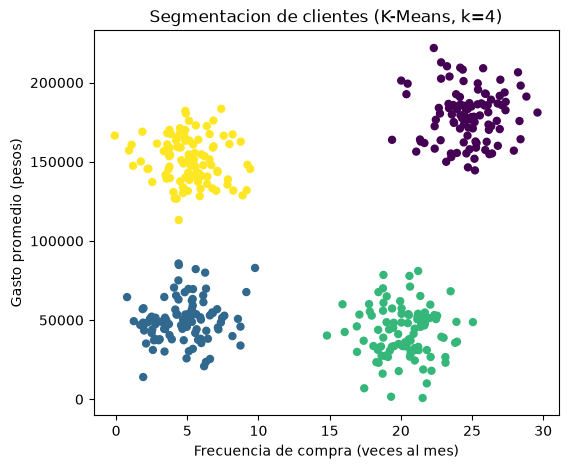

In [15]:
# El metodo del codo sugiere k=4 (donde la curva deja de bajar fuertemente), que coincide
# con los 4 grupos reales que se usaron para generar los datos
kmeans_final = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)  # modelo final con k=4
grupos_asignados = kmeans_final.fit_predict(X_cluster_escalado)  # entrena y asigna cada cliente a un grupo en un solo paso

coeficiente_silueta = silhouette_score(X_cluster_escalado, grupos_asignados)  # mide que tan bien separados quedaron los grupos
print("Coeficiente de silueta:", round(coeficiente_silueta, 3))  # valores cercanos a 1 indican grupos bien definidos

plt.figure(figsize=(6, 5))  # crea una nueva figura
plt.scatter(X_cluster[:, 0], X_cluster[:, 1], c=grupos_asignados, cmap="viridis", s=25)  # grafica los puntos originales, coloreados por grupo
plt.xlabel("Frecuencia de compra (veces al mes)")  # etiqueta del eje horizontal, en la escala original (no escalada)
plt.ylabel("Gasto promedio (pesos)")  # etiqueta del eje vertical, en la escala original
plt.title("Segmentacion de clientes (K-Means, k=4)")  # titulo de la grafica
plt.show()  # muestra la grafica


## 6. Reduccion de dimensionalidad (PCA)

Cuando un dataset tiene muchas variables, suele ser util reducirlo a dos o tres
dimensiones que conserven la mayor cantidad de informacion posible, tanto para
visualizar los datos como para simplificar el trabajo de otros algoritmos. El Analisis
de Componentes Principales (PCA) es la tecnica estandar para esto. Aqui se aplica sobre
las variables numericas del dataset de churn de la seccion 2.

In [16]:
# Se usan solo las columnas numericas del dataset de churn, ya escaladas,
# porque PCA (igual que K-Means) se basa en distancias y es sensible a la escala
X_numerico_escalado = StandardScaler().fit_transform(datos[columnas_numericas].fillna(datos[columnas_numericas].median()))
# fillna con la mediana: PCA no acepta valores faltantes, asi que se imputan antes de escalar

pca = PCA(n_components=2, random_state=RANDOM_STATE)  # se reduce a 2 componentes, para poder graficar en dos dimensiones
X_pca = pca.fit_transform(X_numerico_escalado)  # ajusta PCA y transforma los datos en un solo paso

varianza_explicada = pca.explained_variance_ratio_  # proporcion de la variabilidad original que conserva cada componente
print("Varianza explicada por cada componente:", varianza_explicada.round(3))
print("Varianza explicada total (2 componentes):", round(varianza_explicada.sum(), 3))


Varianza explicada por cada componente: [0.351 0.334]
Varianza explicada total (2 componentes): 0.685


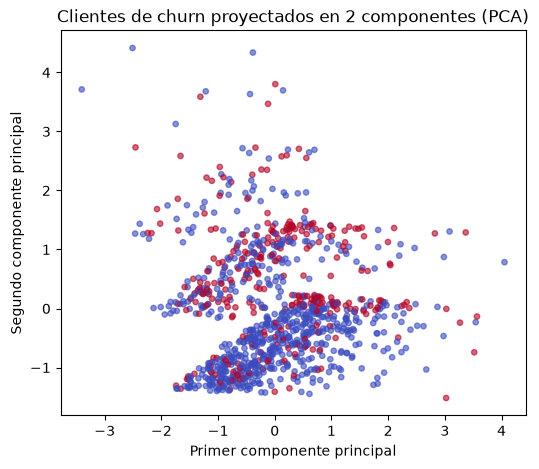

In [17]:
plt.figure(figsize=(6, 5))  # crea una figura
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=datos["cancela"], cmap="coolwarm", s=15, alpha=0.6)  # grafica los clientes en el espacio reducido, coloreados por si cancelaron
plt.xlabel("Primer componente principal")  # etiqueta del eje horizontal
plt.ylabel("Segundo componente principal")  # etiqueta del eje vertical
plt.title("Clientes de churn proyectados en 2 componentes (PCA)")  # titulo de la grafica
plt.show()  # muestra la grafica


## 7. Aprendizaje por refuerzo: Q-learning desde cero

A diferencia de las secciones anteriores, aqui no se usa scikit-learn porque el
aprendizaje por refuerzo no encaja en el patron de "entrenar con datos ya existentes".
En su lugar, se construye desde cero un entorno simple (una grilla de 4x4) y un agente
que aprende, mediante el algoritmo Q-learning, la ruta que maximiza su recompensa: llegar
a la meta evitando un obstaculo, sin que nadie le diga de antemano cual es el camino
correcto.

In [18]:
# Definicion del entorno: una grilla de 4x4 (16 estados posibles), numerados de 0 a 15
# por fila, de izquierda a derecha y de arriba hacia abajo
TAMANO_GRILLA = 4  # numero de filas y columnas de la grilla
NUMERO_ESTADOS = TAMANO_GRILLA * TAMANO_GRILLA  # numero total de celdas en la grilla
ESTADO_META = 15  # la celda inferior derecha es la meta
ESTADO_OBSTACULO = 9  # una celda intermedia que el agente debe evitar

ACCIONES = ["arriba", "abajo", "izquierda", "derecha"]  # las 4 acciones posibles en cada paso
NUMERO_ACCIONES = len(ACCIONES)  # numero de acciones disponibles


def mover(estado, accion):
    """Calcula el nuevo estado al ejecutar una accion desde un estado dado.

    Si la accion sacaria al agente de la grilla, el agente simplemente se queda
    en el mismo estado (no se le permite salir del tablero).
    """
    fila = estado // TAMANO_GRILLA  # fila actual, dividiendo el estado entre el tamano de la grilla
    columna = estado % TAMANO_GRILLA  # columna actual, el residuo de esa division

    if accion == "arriba":
        fila = max(fila - 1, 0)  # sube una fila, sin pasar del borde superior
    elif accion == "abajo":
        fila = min(fila + 1, TAMANO_GRILLA - 1)  # baja una fila, sin pasar del borde inferior
    elif accion == "izquierda":
        columna = max(columna - 1, 0)  # se mueve una columna a la izquierda, sin pasar del borde
    elif accion == "derecha":
        columna = min(columna + 1, TAMANO_GRILLA - 1)  # se mueve una columna a la derecha, sin pasar del borde

    return fila * TAMANO_GRILLA + columna  # convierte la nueva fila y columna de vuelta a un numero de estado


def recompensa(estado_nuevo):
    """Define la recompensa que recibe el agente al llegar a un estado dado."""
    if estado_nuevo == ESTADO_META:
        return 10.0  # recompensa alta por llegar a la meta
    if estado_nuevo == ESTADO_OBSTACULO:
        return -10.0  # penalizacion fuerte por caer en el obstaculo
    return -0.1  # pequena penalizacion por cada paso, para incentivar rutas cortas


In [19]:
# Tabla Q: una fila por cada estado, una columna por cada accion, inicializada en cero
# Q[estado, accion] representa que tan buena cree el agente que es tomar esa accion en ese estado
tabla_q = np.zeros((NUMERO_ESTADOS, NUMERO_ACCIONES))

# Hiperparametros del algoritmo de Q-learning
TASA_APRENDIZAJE = 0.1      # que tanto se actualiza la tabla Q en cada paso (0 = no aprende, 1 = olvida todo lo anterior)
FACTOR_DESCUENTO = 0.95     # que tanto valora el agente las recompensas futuras frente a las inmediatas
EPSILON_INICIAL = 1.0       # probabilidad inicial de tomar una accion aleatoria (exploracion)
EPSILON_MINIMO = 0.05       # probabilidad minima de exploracion, nunca deja de explorar del todo
TASA_DECAIMIENTO_EPSILON = 0.995  # que tan rapido disminuye epsilon en cada episodio
NUMERO_EPISODIOS = 500      # numero de intentos completos que tendra el agente para aprender
PASOS_MAXIMOS_POR_EPISODIO = 50  # limite de pasos por intento, para evitar bucles infinitos

epsilon = EPSILON_INICIAL  # variable que ira disminuyendo a lo largo del entrenamiento
recompensas_por_episodio = []  # lista para registrar el desempeno del agente a lo largo del entrenamiento

for episodio in range(NUMERO_EPISODIOS):  # repite el proceso de aprendizaje NUMERO_EPISODIOS veces
    estado_actual = 0  # cada episodio el agente arranca en la celda superior izquierda (estado 0)
    recompensa_total_episodio = 0.0  # acumulador de recompensa para este episodio

    for paso in range(PASOS_MAXIMOS_POR_EPISODIO):  # cada episodio dura como maximo PASOS_MAXIMOS_POR_EPISODIO pasos
        if np.random.rand() < epsilon:  # con probabilidad epsilon, el agente explora (accion aleatoria)
            indice_accion = np.random.randint(NUMERO_ACCIONES)  # elige una accion al azar entre las disponibles
        else:
            indice_accion = int(np.argmax(tabla_q[estado_actual]))  # si no explora, elige la accion que la tabla Q considera mejor

        accion_elegida = ACCIONES[indice_accion]  # convierte el indice numerico al nombre de la accion
        estado_siguiente = mover(estado_actual, accion_elegida)  # calcula a que estado lleva esa accion
        r = recompensa(estado_siguiente)  # calcula la recompensa obtenida al llegar a ese nuevo estado
        recompensa_total_episodio += r  # acumula esa recompensa en el total del episodio

        # Actualizacion de Q-learning: se ajusta el valor Q del estado y accion actuales
        # hacia la recompensa obtenida mas el mejor valor futuro posible desde el nuevo estado
        mejor_valor_futuro = np.max(tabla_q[estado_siguiente])  # el mejor valor Q posible desde el estado al que se llego
        valor_actual = tabla_q[estado_actual, indice_accion]  # el valor Q que la tabla tenia antes de esta actualizacion
        tabla_q[estado_actual, indice_accion] = valor_actual + TASA_APRENDIZAJE * (
            r + FACTOR_DESCUENTO * mejor_valor_futuro - valor_actual  # la formula de Q-learning
        )

        estado_actual = estado_siguiente  # el agente se mueve efectivamente al nuevo estado

        if estado_actual in (ESTADO_META, ESTADO_OBSTACULO):  # si llego a la meta o al obstaculo, el episodio termina
            break  # corta el bucle de pasos antes de llegar al limite

    recompensas_por_episodio.append(recompensa_total_episodio)  # guarda el resultado de este episodio para analizarlo despues
    epsilon = max(EPSILON_MINIMO, epsilon * TASA_DECAIMIENTO_EPSILON)  # reduce epsilon, pero nunca por debajo del minimo


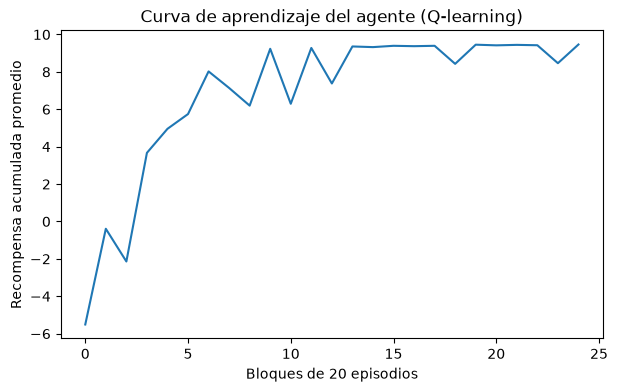

La recompensa promedio deberia subir con el tiempo: el agente aprende a evitar el obstaculo y llegar a la meta.


In [20]:
plt.figure(figsize=(7, 4))  # crea una figura
# Se promedia la recompensa en bloques de 20 episodios, para suavizar la curva y que la tendencia sea visible
tamano_bloque = 20  # numero de episodios por bloque de promedio
promedios_por_bloque = [
    np.mean(recompensas_por_episodio[i:i + tamano_bloque])  # promedio de recompensa dentro de cada bloque
    for i in range(0, NUMERO_EPISODIOS, tamano_bloque)  # itera sobre los episodios en pasos de tamano_bloque
]
plt.plot(promedios_por_bloque)  # grafica la recompensa promedio por bloque de episodios
plt.xlabel(f"Bloques de {tamano_bloque} episodios")  # etiqueta del eje horizontal
plt.ylabel("Recompensa acumulada promedio")  # etiqueta del eje vertical
plt.title("Curva de aprendizaje del agente (Q-learning)")  # titulo de la grafica
plt.show()  # muestra la grafica

print("La recompensa promedio deberia subir con el tiempo: el agente aprende a evitar el obstaculo y llegar a la meta.")


In [21]:
# Una vez entrenada la tabla Q, se puede extraer la ruta que el agente considera optima
# desde el estado inicial, siguiendo siempre la accion de mayor valor Q (sin exploracion)
estado_actual = 0  # se parte de nuevo desde la celda inicial
ruta_aprendida = [estado_actual]  # lista que ira guardando cada estado visitado

for paso in range(PASOS_MAXIMOS_POR_EPISODIO):  # se limita el numero de pasos, por seguridad
    mejor_accion = ACCIONES[int(np.argmax(tabla_q[estado_actual]))]  # elige siempre la accion de mayor valor Q
    estado_actual = mover(estado_actual, mejor_accion)  # ejecuta esa accion y obtiene el siguiente estado
    ruta_aprendida.append(estado_actual)  # agrega el nuevo estado a la ruta

    if estado_actual in (ESTADO_META, ESTADO_OBSTACULO):  # si llega a la meta o al obstaculo, se detiene
        break

print("Ruta aprendida (en numeros de celda):", ruta_aprendida)
print("Resultado final:", "llego a la meta" if ruta_aprendida[-1] == ESTADO_META else "cayo en el obstaculo")


Ruta aprendida (en numeros de celda): [0, 1, 2, 6, 7, 11, 15]
Resultado final: llego a la meta


## Cierre

Este notebook cubrio, de forma practica y comentada linea a linea, el ciclo completo de
trabajo con los tres paradigmas de machine learning vistos en la Unidad 2.1: preprocesar
datos reales (con faltantes y variables categoricas), entrenar y evaluar modelos
supervisados de clasificacion y regresion, comparar modelos con validacion cruzada,
segmentar datos sin etiquetas con clustering, reducir dimensionalidad con PCA, y construir
un agente de aprendizaje por refuerzo desde cero con Q-learning.

Para el proyecto final, el ejercicio equivalente es tomar datos reales (o lo mas realistas
posible) de la organizacion elegida, y adaptar alguno de estos flujos de trabajo al
problema de negocio identificado.